In [2]:
import sys
sys.path.append("../")
sys.path.append("../../src")
from collision_scores import compute_collision_counts_and_length
from run_all_score_calculations import load_history_dump, reformat_history, filter_bat_positions_from_history
from supporting_files.utilities import load_parameters
from polarization_score import compute_polarization
import matplotlib.pyplot as plt
import numpy as np

In [23]:
dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/multirun/2026-08-25/18-31-17/1"
bat_positions_raw = load_history_dump(dir)
bat_positions, bat_directions= filter_bat_positions_from_history(bat_positions_raw)
parameters_df = load_parameters(dir+"/parameters_used.json")
print(compute_collision_counts_and_length(bat_positions, parameters_df))
polarization_list = compute_polarization(bat_directions)

(345, 122)


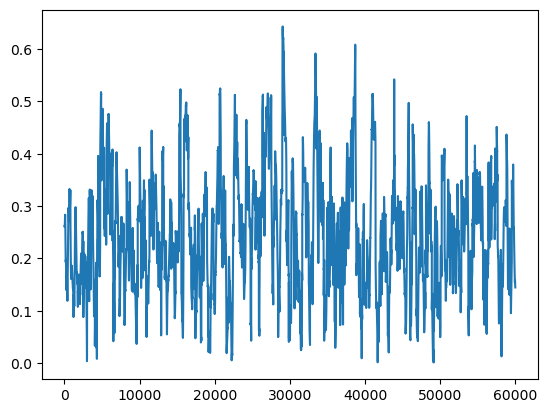

(0.0, 1.0)

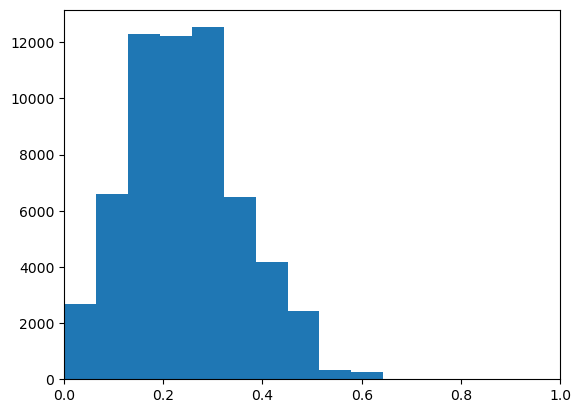

In [24]:


plt.plot(polarization_list)
plt.show()
plt.hist(polarization_list)
plt.xlim(0,1)

In [25]:
np.mean(polarization_list), np.median(polarization_list)

(0.24448359, 0.237156)

In [26]:
dir = "/home/adityamoger/Documents/GitHub/bat-swarm-model/multirun/2026-08-25/18-31-17/2"
bat_positions_raw = load_history_dump(dir)
bat_positions, bat_directions= filter_bat_positions_from_history(bat_positions_raw)
parameters_df = load_parameters(dir+"/parameters_used.json")
compute_collision_counts_and_length(bat_positions, parameters_df)
polarization_list_control = compute_polarization(bat_directions)

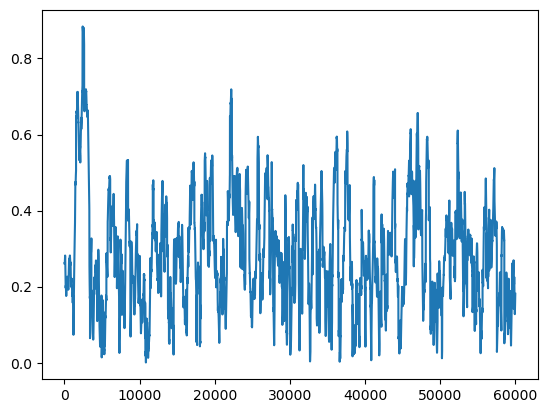

(0.0, 1.0)

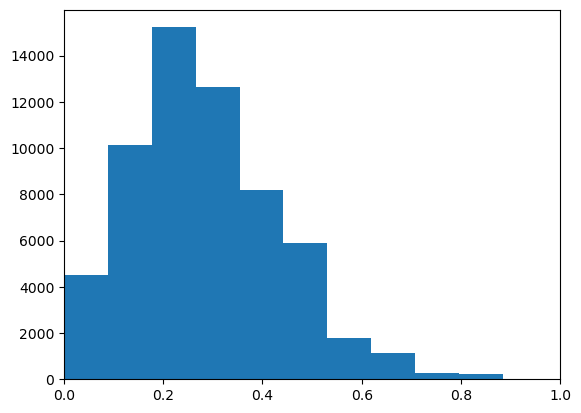

In [27]:


plt.plot(polarization_list_control)
plt.show()
plt.hist(polarization_list_control)
plt.xlim(0,1)


In [28]:
np.mean(polarization_list_control), np.median(polarization_list_control)

(0.28572503, 0.2665059)

{'bodies': [<matplotlib.collections.PolyCollection at 0x7148be26c650>],
 'cmaxes': <matplotlib.collections.LineCollection at 0x7148b99655e0>,
 'cmins': <matplotlib.collections.LineCollection at 0x7148ba77b200>,
 'cbars': <matplotlib.collections.LineCollection at 0x7148ba797aa0>}

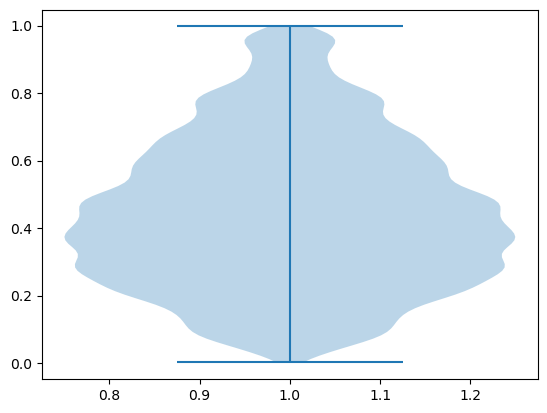

In [8]:
plt.violinplot(polarization_list)

In [29]:
import pandas as pd 
df = pd.DataFrame(columns = ["label", "scores"])
label_tr = ["treatment"] * len(polarization_list)
label_control = ["control"] * len(polarization_list_control)
label= []
scores = []
label.extend(label_control)
label.extend(label_tr)
scores.extend(polarization_list_control)
scores.extend(polarization_list)
df["label"]= label
df["scores"] = scores
df

,label,scores
0,control,0.261222
1,control,0.261222
2,control,0.261222
3,control,0.261222
4,control,0.261222
...,...,...
119995,treatment,0.147414
119996,treatment,0.146680
119997,treatment,0.145939
119998,treatment,0.145192


<Axes: xlabel='label', ylabel='scores'>

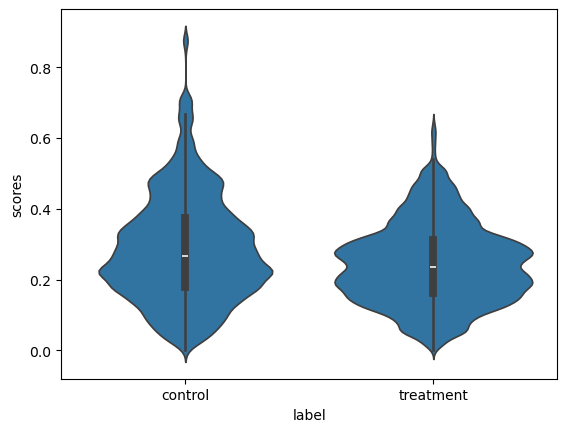

In [30]:
import seaborn as sns
sns.violinplot(data=df, x="label", y="scores")

In [3]:
from scores.calling_effort_score import calling_effort
from scores.collision_scores_single_bat import (
    compute_collision_counts_and_length,
    compute_collision_rate,
)
from scores.milling_score import compute_milling
from scores.nearest_neighbour_distance import compute_nearest_neighbour_distance
from scores.polarization_score import compute_polarization
from scores.space_occupied_scores import space_occupied_score

(60000, 10, 2)


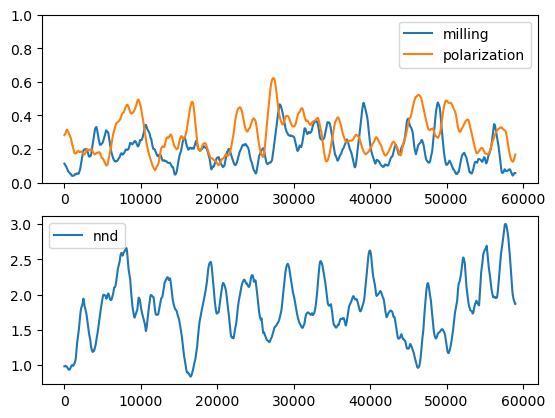

In [19]:
output_dir = r"/home/adityamoger/Documents/GitHub/bat-swarm-model/multirun/2026-09-03/13-52-09/0/"
bat_positions_raw = load_history_dump(output_dir)
bat_positions, bat_directions = filter_bat_positions_from_history(bat_positions_raw)
x = np.array(bat_directions, dtype=np.half)
print(x.shape)

import matplotlib.pyplot as plt

def running_mean(x, N):
    cumsum = np.cumsum(np.insert(x, 0, 0))
    return (cumsum[N:] - cumsum[:-N]) / float(N)

milling_score_timeseries = compute_milling(
    bat_directions=bat_directions, bat_positions=bat_positions
)
polarization_score_timeseries = compute_polarization(bat_directions)
nnd_timeseries = compute_nearest_neighbour_distance(bat_positions)
median_nnd_time_series = np.median(nnd_timeseries, axis=1)

milling_score_timeseries = running_mean(milling_score_timeseries, 1000)
polarization_score_timeseries = running_mean(polarization_score_timeseries, 1000)
median_nnd_time_series = running_mean(median_nnd_time_series, 1000)
plt.subplot(2, 1, 1)
plt.plot(milling_score_timeseries, label="milling")
plt.plot(polarization_score_timeseries, label="polarization")
plt.ylim(0,1)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(median_nnd_time_series, label="nnd")
plt.legend()
plt.show()

(60000, 10, 2)


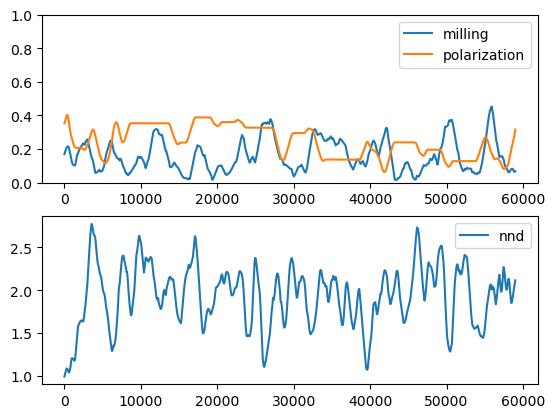

In [20]:
output_dir = r"/home/adityamoger/Documents/GitHub/bat-swarm-model/multirun/2026-09-03/13-52-09/1/"
bat_positions_raw = load_history_dump(output_dir)
bat_positions, bat_directions = filter_bat_positions_from_history(bat_positions_raw)
x = np.array(bat_directions, dtype=np.half)
print(x.shape)

milling_score_timeseries_control = compute_milling(
    bat_directions=bat_directions, bat_positions=bat_positions
)
polarization_score_timeseries_control = compute_polarization(bat_directions)
nnd_timeseries_control = compute_nearest_neighbour_distance(bat_positions)
median_nnd_time_series_control = np.median(nnd_timeseries_control, axis=1)

milling_score_timeseries_control = running_mean(milling_score_timeseries_control, 1000)
polarization_score_timeseries_control = running_mean(polarization_score_timeseries_control, 1000)
median_nnd_time_series_control = running_mean(median_nnd_time_series_control, 1000)
plt.subplot(2, 1, 1)
plt.plot(milling_score_timeseries_control, label="milling")
plt.plot(polarization_score_timeseries_control, label="polarization")
plt.ylim(0,1)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(median_nnd_time_series_control, label="nnd")
plt.legend()
plt.show()

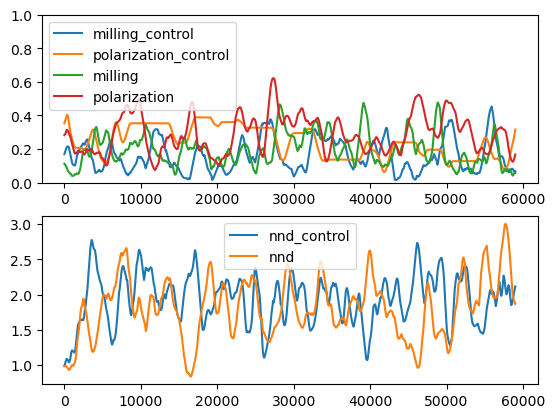

In [21]:
plt.subplot(2, 1, 1)
plt.plot(milling_score_timeseries_control, label="milling_control")
plt.plot(polarization_score_timeseries_control, label="polarization_control")
plt.plot(milling_score_timeseries, label="milling")
plt.plot(polarization_score_timeseries, label="polarization")
plt.ylim(0,1)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(median_nnd_time_series_control, label="nnd_control")
plt.plot(median_nnd_time_series, label="nnd")
plt.legend()
plt.show()

